# Лабораторная работа 4. Бонус. Проверка нормальности

Проверим четыре признака ирисов Фишера с помощью критерия χ² Пирсона. Из таблицы признаков уберём номер и название сорта. Названия сортов сохраним отдельно, чтобы затем использовать их для группировки.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

alpha = 0.05
import matplotlib.pyplot as plt

raw = pd.read_excel('Iris.xlsx', sheet_name='Data')
raw.index = range(1, len(raw) + 1)
species = raw['Species_name'].str.strip().replace({'Verginica': 'Virginica'})
df = raw.drop(columns=['Species_No', 'Species_name']).rename(columns={
    'Petal_width': 'Ширина лепестка',
    'Petal_length': 'Длина лепестка',
    'Sepal_width': 'Ширина чашелистика',
    'Sepal_length': 'Длина чашелистика',
})
print(df.head().to_string())
print()
print(species.value_counts().to_string())

   Ширина лепестка  Длина лепестка  Ширина чашелистика  Длина чашелистика
1              0.2             1.4                 3.5                5.1
2              0.2             1.4                 3.0                4.9
3              0.2             1.3                 3.2                4.7
4              0.2             1.5                 3.1                4.6
5              0.2             1.4                 3.6                5.0

Species_name
Setosa        50
Versicolor    50
Virginica     50


## Как работает Gauss

Для каждого признака считаем среднее, медиану, асимметрию и эксцесс. У нормального распределения среднее и медиана совпадают, а асимметрия и эксцесс равны нулю. В выборке эти значения могут отличаться.

По выборке оцениваем среднее и стандартное отклонение. Квантили полученной нормальной кривой дают шесть равновероятных интервалов. Первый начинается с −∞, последний заканчивается на +∞. В каждый интервал должно попасть в среднем n / 6 наблюдений. Даже для группы из 50 цветков это 8,33.

Критерий Пирсона складывает (O − E)² / E по всем интервалам. O обозначает наблюдаемую частоту, E обозначает ожидаемую. Для приближённой оценки p берём 6 − 1 − 2 = 3 степени свободы. Единицу вычитаем из-за фиксированной суммы частот, двойку за два параметра, оценённых по выборке. Результат зависит от границ интервалов и округления исходных измерений.

In [2]:
def Gauss(x, title):
    x = x.dropna()
    n = len(x)
    mu, sigma = stats.norm.fit(x)
    bins = 6
    edges = stats.norm.ppf(np.linspace(0, 1, bins + 1), loc=mu, scale=sigma)
    obs = np.histogram(x, bins=edges)[0]
    exp = np.full(bins, n / bins)
    assert obs.sum() == n and exp.min() >= 5
    chi2, p = stats.chisquare(obs, f_exp=exp, ddof=2)

    print(title)
    print(f'n = {n}, среднее = {mu:.3f}, медиана = {x.median():.3f}')
    skew = stats.skew(x, bias=False)
    kurt = stats.kurtosis(x, fisher=True, bias=False)
    print(f'Асимметрия = {skew:.3f}, эксцесс = {kurt:.3f}')
    print('H₀: распределение нормальное.')
    print('H₁: распределение отличается от нормального.')
    print(f'Границы интервалов: {edges.round(3).tolist()}')
    print(f'Наблюдаемые частоты: {obs.tolist()}. Ожидаемая частота: {exp[0]:.2f}.')
    print(f'χ² = {chi2:.3f}, степеней свободы: {bins - 3}, p = {p:.6g}')
    if p < alpha:
        print('При α = 0,05 отклоняем H₀.')
    else:
        print('При α = 0,05 нет оснований отклонить H₀.')

    fig, ax = plt.subplots(figsize=(6, 2.8), layout='constrained')
    grid = np.linspace(x.min(), x.max(), 200)
    ax.hist(x, bins=12, density=True, color='0.78', edgecolor='white')
    ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color='black', label='Нормальная кривая')
    ax.legend(frameon=False)
    ax.set(title=title, xlabel='см', ylabel='Плотность')
    plt.show()
    return p

## Все цветки вместе

У нормальной выборки среднее и медиана обычно близки, а асимметрия и эксцесс колеблются около нуля.

Ширина лепестка
n = 150, среднее = 1.199, медиана = 1.300
Асимметрия = -0.103, эксцесс = -1.341
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 0.464, 0.872, 1.199, 1.527, 1.934, inf]
Наблюдаемые частоты: [48, 2, 10, 38, 23, 29]. Ожидаемая частота: 25.00.
χ² = 58.880, степеней свободы: 3, p = 1.01974e-12
При α = 0,05 отклоняем H₀.


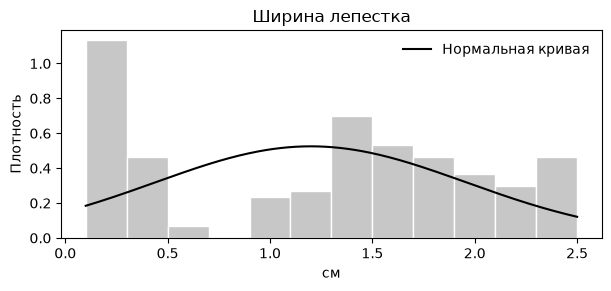

Длина лепестка
n = 150, среднее = 3.758, медиана = 4.350
Асимметрия = -0.275, эксцесс = -1.402
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 2.056, 3.0, 3.758, 4.516, 5.46, inf]
Наблюдаемые частоты: [50, 1, 6, 30, 35, 28]. Ожидаемая частота: 25.00.
χ² = 67.840, степеней свободы: 3, p = 1.23788e-14
При α = 0,05 отклоняем H₀.


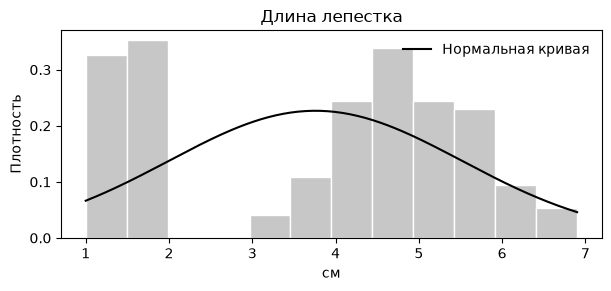

Ширина чашелистика
n = 150, среднее = 3.057, медиана = 3.000
Асимметрия = 0.319, эксцесс = 0.228
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 2.637, 2.87, 3.057, 3.244, 3.478, inf]
Наблюдаемые частоты: [24, 23, 36, 24, 18, 25]. Ожидаемая частота: 25.00.
χ² = 7.040, степеней свободы: 3, p = 0.0706337
При α = 0,05 нет оснований отклонить H₀.


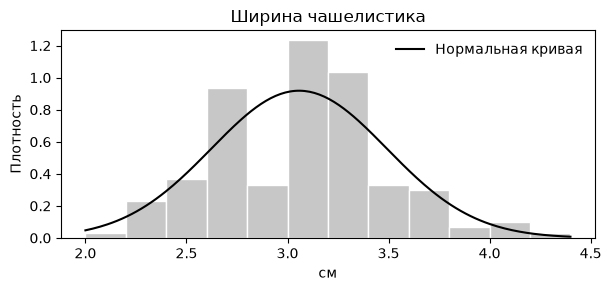

Длина чашелистика
n = 150, среднее = 5.843, медиана = 5.800
Асимметрия = 0.315, эксцесс = -0.552
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 5.045, 5.488, 5.843, 6.199, 6.642, inf]
Наблюдаемые частоты: [32, 20, 28, 15, 27, 28]. Ожидаемая частота: 25.00.
χ² = 7.840, степеней свободы: 3, p = 0.0494368
При α = 0,05 отклоняем H₀.


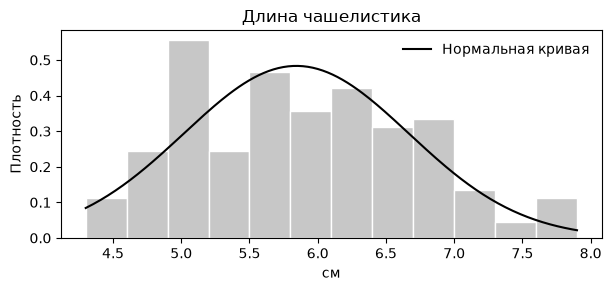

Минимальное p-значение у показателя «Длина лепестка»: 1.23788e-14.


In [3]:
pvals = {}
for col in df:
    pvals[col] = Gauss(df[col], col)

col_min = min(pvals, key=pvals.get)
print(f'Минимальное p-значение у показателя «{col_min}»: {pvals[col_min]:.6g}.')

Для длины лепестка в первый интервал попало 50 цветков при ожидаемых 25. Вклад этого интервала в χ² равен (50 − 25)² / 25 = 25. По всем шести интервалам сумма равна 67,84.

## Проверка по сортам

Длина лепестка (Setosa)
n = 50, среднее = 1.462, медиана = 1.500
Асимметрия = 0.106, эксцесс = 1.022
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 1.296, 1.388, 1.462, 1.536, 1.628, inf]
Наблюдаемые частоты: [4, 7, 13, 13, 7, 6]. Ожидаемая частота: 8.33.
χ² = 8.560, степеней свободы: 3, p = 0.0357507
При α = 0,05 отклоняем H₀.


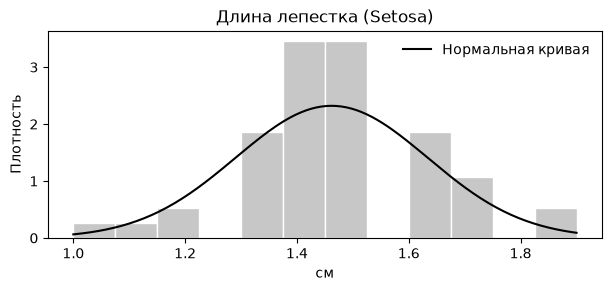

Длина лепестка (Versicolor)
n = 50, среднее = 4.260, медиана = 4.350
Асимметрия = -0.607, эксцесс = 0.048
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 3.81, 4.06, 4.26, 4.46, 4.71, inf]
Наблюдаемые частоты: [8, 8, 7, 6, 15, 6]. Ожидаемая частота: 8.33.
χ² = 6.880, степеней свободы: 3, p = 0.0758225
При α = 0,05 нет оснований отклонить H₀.


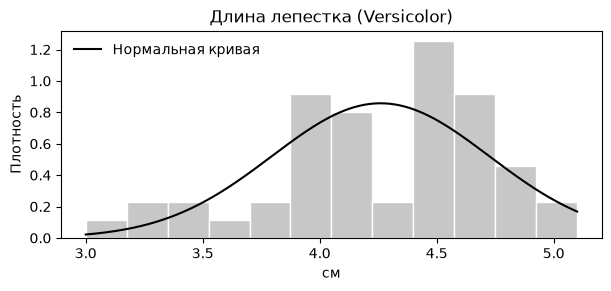

Длина лепестка (Virginica)
n = 50, среднее = 5.552, медиана = 5.550
Асимметрия = 0.549, эксцесс = -0.154
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 5.023, 5.317, 5.552, 5.787, 6.081, inf]
Наблюдаемые частоты: [9, 11, 5, 9, 7, 9]. Ожидаемая частота: 8.33.
χ² = 2.560, степеней свободы: 3, p = 0.464545
При α = 0,05 нет оснований отклонить H₀.


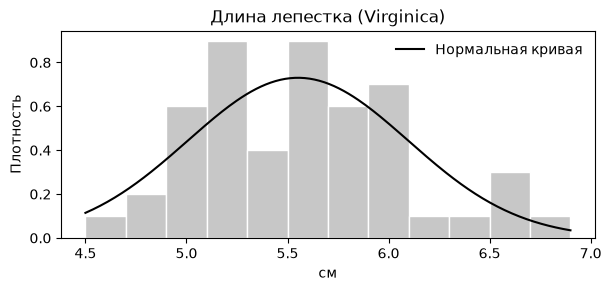

In [4]:
for name in species.unique():
    Gauss(df.loc[species == name, col_min], f'{col_min} ({name})')

## Мелкие и крупные цветки

К мелким относим Setosa. К крупным относим Versicolor и Virginica вместе.

Длина лепестка (мелкие)
n = 50, среднее = 1.462, медиана = 1.500
Асимметрия = 0.106, эксцесс = 1.022
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 1.296, 1.388, 1.462, 1.536, 1.628, inf]
Наблюдаемые частоты: [4, 7, 13, 13, 7, 6]. Ожидаемая частота: 8.33.
χ² = 8.560, степеней свободы: 3, p = 0.0357507
При α = 0,05 отклоняем H₀.


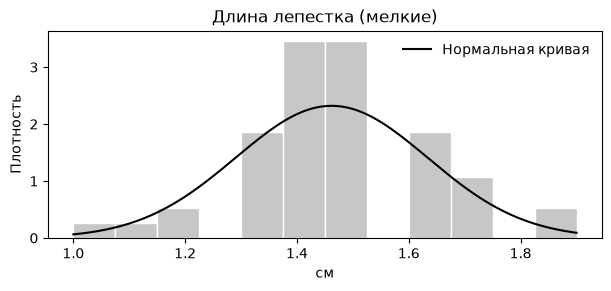

Длина лепестка (крупные)
n = 100, среднее = 4.906, медиана = 4.900
Асимметрия = 0.171, эксцесс = -0.325
H₀: распределение нормальное.
H₁: распределение отличается от нормального.
Границы интервалов: [-inf, 4.111, 4.552, 4.906, 5.26, 5.701, inf]
Наблюдаемые частоты: [19, 18, 17, 14, 16, 16]. Ожидаемая частота: 16.67.
χ² = 0.920, степеней свободы: 3, p = 0.820599
При α = 0,05 нет оснований отклонить H₀.


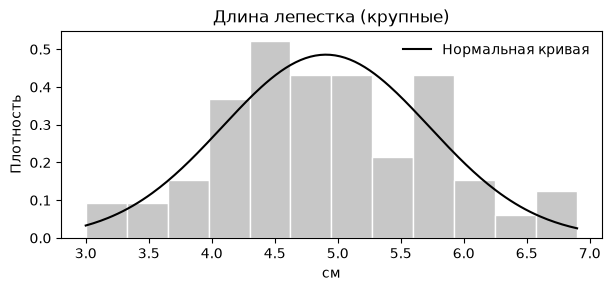

np.float64(0.8205988623005103)

In [5]:
small = species == 'Setosa'
Gauss(df.loc[small, col_min], f'{col_min} (мелкие)')
Gauss(df.loc[~small, col_min], f'{col_min} (крупные)')

## Вывод

В общей выборке при α = 0,05 нормальность отклоняется для ширины и длины лепестка и для длины чашелистика. Для ширины чашелистика оснований отклонить нормальность нет (p = 0,07063). Длина чашелистика даёт пограничное значение p = 0,04944.

Наименьшее p у длины лепестка (1,24 × 10⁻¹⁴). На общей гистограмме видно, что короткие лепестки Setosa отделены от более длинных лепестков остальных сортов.

При проверке по сортам нормальность отклоняется для Setosa (p = 0,03575). Это же результат для мелких цветков. Для Versicolor (p = 0,07582), Virginica (p = 0,46455) и для их объединения в группу крупных цветков (p = 0,82060) оснований отклонить нормальность нет.